# Notebook 06 — FDIC Bank Failure Prediction | Part 5: Modelling & Validation
**BFT65B · Bank Failure Early Warning · Stage A development → Stage B single final Test**

This notebook is a direct continuation of **Notebook 05 (Part 4)**. It reads previously created, train-fitted, model-ready Parquet files; **it never refits preprocessing**, never changes the time-based split and never uses TEST for model/feature/threshold selection.

**Research design**
- Target: a confirmed FDIC bank failure within the **next four calendar quarters**.
- Input features: preprocessed historical financial ratios (lagged one quarter in Part 4).
- TRAIN: **1984Q1–2005Q4**, VALIDATION: **2007Q1–2011Q4**, TEST: **2013Q1–2025Q2**. Two 4-quarter embargo intervals separate the development and test stages.
- Training: baseline prior probability and logistic regression; candidate models: regularized logistic regression, Random Forest, Histogram Gradient Boosting. Evaluate **Core (24)** and **Extended (26)** source-feature families (plus missingness indicators) without refitting the Part 4 preprocessing.
- Selection: **VALIDATION Average Precision**, ROC-AUC and Brier as supporting diagnostics; choose one model without looking at TEST.
- Alarm rule: minimize **estimated VALIDATION false-alert costs + missed bank failures**, using *development-only* FDIC failure COST as a severity proxy and explicitly assumed extra-review cost for false alarms. Report sensitivity to the assumed inspection cost.
- PySpark MLlib: separate **demonstration on development data only** (not the production winner).
- TEST: **one locked evaluation only**. By default `RUN_FINAL_TEST = False`; change it only after checking the development report.

> **Important caveat:** A bank may contribute several overlapping positive bank-quarters. The economic loss of missing a failure is therefore counted **once per distinct bank**, while false alarms are counted **per negative bank-quarter**. FDIC `COST` is an estimated DIF resolution loss, **not** the known preventable loss from a missed warning. False-alarm examination cost is **not observed** in the FDIC tables; the assumed fractions are labeled sensitivity assumptions, not FDIC estimates.

**No real performance figures are embedded in this notebook.** The results must be generated in the user's Colab runtime.

## 0. Libraries and execution switches
This notebook is designed for Google Colab. Run in order. First keep `RUN_FINAL_TEST=False` and review the development report. Later change only the switch and rerun the last **FINAL TEST** section in the same session, or restart and rerun the notebook under the frozen protocol (the one-test guard still applies).

In [ ]:
%pip -q install "pandas>=2.2,<3" "numpy>=1.26,<3" "pyarrow>=15,<26" "scikit-learn>=1.5,<2" "matplotlib>=3.7,<4" "joblib>=1.3,<2" "pyspark>=3.5,<5"

In [ ]:
import os, sys, json, hashlib, platform, zipfile, time, warnings, random
from pathlib import Path
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (average_precision_score, roc_auc_score, brier_score_loss,
                             precision_score, recall_score, f1_score, confusion_matrix,
                             precision_recall_curve, roc_curve)
import joblib

SEED = 65
np.random.seed(SEED)
random.seed(SEED)
ROOT_OVERRIDE = os.environ.get('FDIC_PROJECT_ROOT')
if ROOT_OVERRIDE:
    ROOT = Path(ROOT_OVERRIDE).expanduser().resolve()
else:
    from google.colab import drive
    drive.mount('/content/drive')
    ROOT = Path('/content/drive/MyDrive/FDIC_Bank_Failure_Project')
MODEL_DATA = ROOT / 'data_processed/feature_panel_v1/preprocessed_v1'
REPORT4 = ROOT / 'outputs/part4/feature_pipeline_stage1_v1'
AUX = ROOT / 'data_raw/fdic/aux_pages/failures'
OUT = ROOT / 'outputs/part5/modeling_validation_v1'
OUT.mkdir(parents=True,exist_ok=True)

# Controls. Change RUN_FINAL_TEST only after development is finalized.
RUN_RANDOM_FOREST = True
RUN_SPARK_MLLIB = True
RUN_FINAL_TEST = False
ALLOW_TEST_REEVALUATION = False  # Preserve the holdout. Strongly recommended: always False.

# FDIC COST is for severity proxy only; FALSE_ALARM_COST_FRACTION is a declared assumption.
FALSE_ALARM_COST_FRACTION = 0.01
SENSITIVITY_FRACTIONS = (0.001, 0.005, 0.01, 0.025, 0.05)
PRIMARY_SELECTION_METRIC = 'validation_average_precision'

for f in ['train_model_ready.parquet','validation_model_ready.parquet','test_model_ready.parquet']:
    assert (MODEL_DATA/f).is_file(), f'Missing Part 4 output: {MODEL_DATA/f}'
assert (REPORT4/'preprocessing_manifest.json').is_file()
assert (REPORT4/'stage1_manifest.json').is_file()
assert (REPORT4/'split_counts_and_failures.csv').is_file()
PREP_INFO = json.loads((REPORT4/'preprocessing_manifest.json').read_text(encoding='utf-8'))
SPLIT_INFO = json.loads((REPORT4/'stage1_manifest.json').read_text(encoding='utf-8'))
assert PREP_INFO['fit_split']=='TRAIN_ONLY'
assert PREP_INFO['test_not_used_for_fitting'] is True
assert PREP_INFO['validation_not_used_for_fitting'] is True
assert int(SPLIT_INFO['feature_lag_quarters'])==1
assert int(SPLIT_INFO['label_horizon_quarters'])==4
assert SPLIT_INFO['split_bounds']=={
 'TRAIN':['1984Q1','2005Q4'],
 'VALIDATION':['2007Q1','2011Q4'],
 'TEST':['2013Q1','2025Q2']}
assert 0 < FALSE_ALARM_COST_FRACTION < 1
print('Part 4 verified | ROOT:',ROOT)
print('Versions: Python',platform.python_version(),'pandas',pd.__version__,'sklearn',sklearn.__version__)
print('TEST is locked (default):', not RUN_FINAL_TEST)

Mounted at /content/drive
Part 4 verified | ROOT: /content/drive/MyDrive/FDIC_Bank_Failure_Project
Versions: Python 3.13.18 pandas 2.2.3 sklearn 1.6.1
TEST is locked (default): True


## 1. Verify schema and load **development data only**
Only TRAIN and VALIDATION are loaded here. TEST must not be read until the final, gated cell. Maintain identical feature names and order. `CERT`, `REPDTE`, `Q_ORD` and `fail_within_4q` are metadata/target, never predictors.

In [ ]:
META=['CERT','REPDTE','Q_ORD','fail_within_4q']
BAN_PREDICTOR_TOKENS=('FAILDATE','ENDEF','ACTIVE','EVENT','HISTORY','REVISED_EXIT','SPLIT','LABEL_STATUS')
source_feature_names=list(PREP_INFO['selected_features'])
assert len(source_feature_names)==26
schema=pq.read_schema(MODEL_DATA/'train_model_ready.parquet')
FEATURES=[x for x in schema.names if x not in META]
assert len(FEATURES)==int(PREP_INFO['features_after_transform'])==48
assert not (set(META) & set(FEATURES))
assert not any(any(tok in c.upper() for tok in BAN_PREDICTOR_TOKENS) for c in FEATURES)
for name in ('validation','test'):
    other=pq.read_schema(MODEL_DATA/f'{name}_model_ready.parquet')
    assert other.names==schema.names, (name,'schema/column order mismatch')

# Coverage rule was fixed by TRAIN in Part 4; never examine TEST coverage for selection.
cov=pd.read_csv(REPORT4/'feature_coverage_by_split.csv')
train_cov=cov.loc[cov['split']=='TRAIN'].set_index('feature')['coverage']
CORE_RAW=[f for f in source_feature_names if float(train_cov.loc[f])>=0.90]
EXTENDED_RAW=list(source_feature_names)
assert len(CORE_RAW)==24 and len(EXTENDED_RAW)==26, (len(CORE_RAW),len(EXTENDED_RAW))
def transformed_group(raw_group):
    # sklearn SimpleImputer(add_indicator=True) names are missingindicator_<raw feature>.
    return [c for c in FEATURES if c in raw_group or
            (c.startswith('missingindicator_') and c[len('missingindicator_'):] in raw_group)]
FEATURE_SETS={'CORE':transformed_group(CORE_RAW),'EXTENDED':transformed_group(EXTENDED_RAW)}
assert set(FEATURE_SETS['EXTENDED'])==set(FEATURES)
assert len(FEATURE_SETS['CORE'])>=len(CORE_RAW)
print('Core raw:',len(CORE_RAW),'| Extended raw:',len(EXTENDED_RAW))
print('Transformed columns:',{k:len(v) for k,v in FEATURE_SETS.items()})

def load_split(split):
    df=pd.read_parquet(MODEL_DATA/f'{split.lower()}_model_ready.parquet',columns=META+FEATURES)
    assert all(df[c].notna().all() for c in META)
    assert not df[['CERT','REPDTE']].duplicated().any()
    assert df['fail_within_4q'].isin([0,1]).all()
    vals=df[FEATURES].to_numpy(dtype=np.float32,copy=True)
    assert np.isfinite(vals).all(),f'{split}: nonfinite feature'
    assert df[FEATURES].columns.tolist()==FEATURES
    df[FEATURES]=df[FEATURES].astype('float32')
    return df
train=load_split('TRAIN'); val=load_split('VALIDATION')
expected=pd.read_csv(REPORT4/'split_counts_and_failures.csv').set_index('split')
for split,frame in [('TRAIN',train),('VALIDATION',val)]:
    assert len(frame)==int(expected.loc[split,'rows'])
    assert int((frame.fail_within_4q==1).sum())==int(expected.loc[split,'positive_bank_quarters'])
    assert int(frame.loc[frame.fail_within_4q.eq(1),'CERT'].nunique())==int(expected.loc[split,'distinct_failed_banks'])
print('Development only:',[(n,len(d),int(d.fail_within_4q.sum())) for n,d in [('TRAIN',train),('VALIDATION',val)]])

Core raw: 24 | Extended raw: 26
Transformed columns: {'CORE': 44, 'EXTENDED': 48}
Development only: [('TRAIN', 1084227, 8278), ('VALIDATION', 158131, 1791)]


## 2. Evaluation functions
**Average Precision** (non-interpolated AP) is the primary ranking criterion for extremely rare failures. Always report the positive prevalence alongside it: AP depends on prevalence. ROC-AUC, Brier, and fixed-threshold metrics are secondary. Repeated quarters from the same bank mean row-level scores should not be treated as independent observations for confidence intervals.

In [ ]:
def ranking_metrics(y,prob,split,model):
    y=np.asarray(y,dtype=np.int8)
    p=np.asarray(prob,dtype=np.float64)
    assert len(y)==len(p) and np.isfinite(p).all() and (p>=0).all() and (p<=1).all()
    assert len(np.unique(y))==2, f'{split}: no variation in target'
    return {'split':split,'model':model,'n':int(len(y)),
            'positive':int(y.sum()),'prevalence':float(y.mean()),
            'average_precision':float(average_precision_score(y,p)),
            'roc_auc':float(roc_auc_score(y,p)),
            'brier':float(brier_score_loss(y,p))}

def fixed_threshold_metrics(df,prob,threshold,split,model):
    y=df['fail_within_4q'].to_numpy(dtype='int8')
    pred=np.asarray(prob)>=float(threshold)
    tn,fp,fn,tp=confusion_matrix(y,pred,labels=[0,1]).ravel()
    positive_banks=df.loc[y==1,'CERT'].nunique()
    alerted_positive_banks=df.loc[(y==1)&pred,'CERT'].nunique()
    return {'split':split,'model':model,'threshold':float(threshold),'tn':int(tn),'fp':int(fp),
            'fn_quarters':int(fn),'tp_quarters':int(tp),
            'precision':float(precision_score(y,pred,zero_division=0)),
            'recall_quarters':float(recall_score(y,pred,zero_division=0)),
            'f1':float(f1_score(y,pred,zero_division=0)),
            'false_alerts_per_1000_negative_quarters':float(fp/max(1,(y==0).sum())*1000),
            'failed_banks':int(positive_banks),
            'failed_banks_alerted_within_4q':int(alerted_positive_banks),
            'failed_bank_recall':float(alerted_positive_banks/max(1,positive_banks))}

def cost_curve(frame,prob,c_fn,c_fp):
    # False positives: each negative bank-quarter triggering an inspection.
    # Missed failures: a distinct failing bank with no alarm in its y=1 quarters.
    y=frame.fail_within_4q.to_numpy(dtype=np.int8)
    p=np.asarray(prob,dtype=np.float64)
    negative_scores=np.sort(p[y==0])
    # One maximum alert score per failing bank, evaluated only during its positive quarters.
    maximum_positive_score=(pd.DataFrame({'CERT':frame.loc[y==1,'CERT'].to_numpy(),
                                          'score':p[y==1]})
                             .groupby('CERT',sort=False)['score'].max().to_numpy())
    positive_max=np.sort(maximum_positive_score)
    assert len(positive_max)>=1
    thresholds=np.unique(np.r_[0.0,negative_scores,positive_max,1.0,np.nextafter(1.0,2.0)])
    fp=len(negative_scores)-np.searchsorted(negative_scores,thresholds,side='left')
    fn_banks=np.searchsorted(positive_max,thresholds,side='left')
    cost=fp*float(c_fp)+fn_banks*float(c_fn)
    return pd.DataFrame({'threshold':thresholds,'fp_bank_quarters':fp,
                         'fn_distinct_banks':fn_banks,'estimated_cost':cost,
                         'failed_bank_recall':1-fn_banks/len(positive_max)})

def choose_cost_threshold(frame,prob,c_fn,c_fp):
    curve=cost_curve(frame,prob,c_fn,c_fp)
    min_cost=curve.estimated_cost.min()
    best=(curve.loc[np.isclose(curve.estimated_cost,min_cost,rtol=1e-12,atol=1e-9)]
                .sort_values(['fp_bank_quarters','threshold'],ascending=[True,False]).iloc[0])
    return float(best['threshold']),curve

# Logic tests: a failure counts once even with several positive bank-quarters.
_synth=pd.DataFrame({'CERT':[1,1,2,3,3], 'fail_within_4q':[1,1,1,0,0]})
_synth_p=np.array([.2,.9,.1,.7,.3])
_t,_c=choose_cost_threshold(_synth,_synth_p,100,1)
assert _c.loc[_c['threshold'].eq(.3),'fn_distinct_banks'].iloc[0]==1
assert _c.loc[_c['threshold'].eq(.3),'fp_bank_quarters'].iloc[0]==2
print('Metric & bank-event threshold tests: PASS')

Metric & bank-event threshold tests: PASS


## 3. Candidate models and development-only training
Candidates use the **same historical TRAIN rows**. No random train/test split, no synthetic Test samples. The RF configuration has restrained depth/tree count for Colab memory. Gradient boosting is the primary nonlinear candidate; it is not declared the winner in advance.

In [ ]:
CANDIDATES={
 'LR_L2_CORE': ('CORE',LogisticRegression(C=0.3,solver='lbfgs',max_iter=250,random_state=SEED)),
 'LR_BALANCED_CORE': ('CORE',LogisticRegression(C=0.3,solver='lbfgs',max_iter=250,class_weight='balanced',random_state=SEED)),
 'HGB_CORE': ('CORE',HistGradientBoostingClassifier(learning_rate=0.08,max_iter=110,max_leaf_nodes=15,
               min_samples_leaf=80,l2_regularization=10.0,early_stopping=False,random_state=SEED)),
 'HGB_EXTENDED': ('EXTENDED',HistGradientBoostingClassifier(learning_rate=0.08,max_iter=110,max_leaf_nodes=15,
               min_samples_leaf=80,l2_regularization=10.0,early_stopping=False,random_state=SEED)),
}
if RUN_RANDOM_FOREST:
    CANDIDATES['RF_CORE']=('CORE',RandomForestClassifier(n_estimators=60,max_depth=12,
                   min_samples_leaf=35,max_features='sqrt',n_jobs=2,
                   class_weight='balanced_subsample',random_state=SEED))

Y_TRAIN=train.fail_within_4q.to_numpy(dtype=np.int8)
Y_VAL=val.fail_within_4q.to_numpy(dtype=np.int8)
val_rows=[]
val_scores={}
models={}

# Prior baseline: random ranking => AP approximately the positive prevalence.
prior=DummyClassifier(strategy='prior')
prior.fit(np.zeros((len(train),1),dtype=np.int8),Y_TRAIN)
prior_scores=prior.predict_proba(np.zeros((len(val),1),dtype=np.int8))[:,1]
val_rows.append({**ranking_metrics(Y_VAL,prior_scores,'VALIDATION','DUMMY_PRIOR'),
                 'feature_set':'NONE','train_seconds':0.0})
val_scores['DUMMY_PRIOR']=prior_scores

for name,(group,model) in CANDIDATES.items():
    columns=FEATURE_SETS[group]
    xtr=train[columns].to_numpy(dtype=np.float32,copy=True)
    xva=val[columns].to_numpy(dtype=np.float32,copy=True)
    start=time.perf_counter()
    model.fit(xtr,Y_TRAIN)
    training_seconds=time.perf_counter()-start
    p=model.predict_proba(xva)[:,1]
    models[name]={'model':model,'features':columns,'group':group}
    val_scores[name]=p
    val_rows.append({**ranking_metrics(Y_VAL,p,'VALIDATION',name),
                     'feature_set':group,'train_seconds':round(training_seconds,3)})
    print(f'{name:18s} AP={val_rows[-1]["average_precision"]:.5f} | ROC={val_rows[-1]["roc_auc"]:.4f} | train={training_seconds:.1f}s')

val_results=pd.DataFrame(val_rows).sort_values(['average_precision','roc_auc'],ascending=[False,False])
val_results.to_csv(OUT/'validation_model_comparison.csv',index=False)
print('\nValidation results (no TEST used):')
display(val_results)
WINNER=val_results.loc[val_results['model'].ne('DUMMY_PRIOR'),'model'].iloc[0]
WINNER_INFO=models[WINNER]
VAL_PROB=np.asarray(val_scores[WINNER],dtype=np.float64)
print('Selected by VALIDATION AP:',WINNER)
assert WINNER in models

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LR_L2_CORE         AP=0.42276 | ROC=0.9452 | train=83.0s


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LR_BALANCED_CORE   AP=0.41363 | ROC=0.9618 | train=93.9s
HGB_CORE           AP=0.50038 | ROC=0.9677 | train=38.1s
HGB_EXTENDED       AP=0.49770 | ROC=0.9681 | train=41.0s
RF_CORE            AP=0.49479 | ROC=0.9682 | train=404.9s

Validation results (no TEST used):


,split,model,n,positive,prevalence,average_precision,roc_auc,brier,feature_set,train_seconds
3,VALIDATION,HGB_CORE,158131,1791,0.011326,0.500384,0.967714,0.008163,CORE,38.140
4,VALIDATION,HGB_EXTENDED,158131,1791,0.011326,0.497701,0.968090,0.008194,EXTENDED,41.036
5,VALIDATION,RF_CORE,158131,1791,0.011326,0.494794,0.968170,0.018161,CORE,404.874
1,VALIDATION,LR_L2_CORE,158131,1791,0.011326,0.422755,0.945153,0.008706,CORE,83.016
2,VALIDATION,LR_BALANCED_CORE,158131,1791,0.011326,0.413631,0.961847,0.035275,CORE,93.945
0,VALIDATION,DUMMY_PRIOR,158131,1791,0.011326,0.011326,0.500000,0.011211,NONE,0.000


Selected by VALIDATION AP: HGB_CORE


## 4. Estimate missed-failure severity using DEVELOPMENT ONLY FDIC `COST`
The FDIC `COST` field, when present, is an **estimated loss to the Deposit Insurance Fund**, not the causal saving from early warning. We use the **development-period median positive COST** as a severity scale. The cost of each false alarm is **not observed**: an explicit fraction of that scale is a policy **scenario**. Results must be accompanied by sensitivity tables; do not present this ratio as an FDIC fact.

In [ ]:
def parse_fdic_cost(series):
    s=series.astype('string').str.replace(',','',regex=False).str.replace('$','',regex=False).str.strip()
    return pd.to_numeric(s,errors='coerce')

def find_development_fdic_cost():
    pages=sorted(AUX.glob('snapshot=*/page_*.parquet'))
    if not pages:
        return None,0,'NO_FDIC_FAILURE_PAGES'
    cols=pq.read_schema(pages[0]).names
    if not {'CERT','FAILDATE','COST'}.issubset(cols):
        return None,0,f'MISSING_FIELDS:{sorted(set(["CERT","FAILDATE","COST"])-set(cols))}'
    frames=[pd.read_parquet(p,columns=['CERT','FAILDATE','COST']) for p in pages]
    failures=pd.concat(frames,ignore_index=True)
    failures['FAILDATE_PARSED']=pd.to_datetime(failures['FAILDATE'].astype('string'),errors='coerce',format='mixed')
    failures['CERT_NUM']=pd.to_numeric(failures['CERT'],errors='coerce')
    failures['COST_NUM']=parse_fdic_cost(failures['COST'])
    dev_failed_certs=set(pd.concat([
        train.loc[train.fail_within_4q.eq(1),'CERT'],
        val.loc[val.fail_within_4q.eq(1),'CERT']]).astype('int64').tolist())
    # Use only events observable for the development label horizons through 2012Q4.
    keep=(failures['CERT_NUM'].isin(dev_failed_certs) &
          failures['FAILDATE_PARSED'].between('1984-01-01','2012-12-31') &
          failures['COST_NUM'].gt(0))
    sel=failures.loc[keep,['CERT_NUM','FAILDATE_PARSED','COST_NUM']].drop_duplicates()
    if sel.empty:
        return None,0,'NO_POSITIVE_DEVELOPMENT_COST'
    # Multiple events per CERT are rare; one record per CERT for a conservative median proxy.
    sel=sel.sort_values('FAILDATE_PARSED').drop_duplicates('CERT_NUM',keep='first')
    return float(sel.COST_NUM.median()),int(len(sel)),'FDIC_DEVELOPMENT_COST_MEDIAN'

MEDIAN_COST, COST_N, COST_SOURCE = find_development_fdic_cost()
if MEDIAN_COST is None:
    warnings.warn('No usable development FDIC COST; normalized unit severity=1 is a scenario, not empirical USD cost.')
    C_FN=1.0
else:
    C_FN=MEDIAN_COST
C_FP=float(C_FN)*FALSE_ALARM_COST_FRACTION
cost_manifest={'development_cost_source':COST_SOURCE,
    'development_failures_with_cost':COST_N,
    'median_positive_fdic_cost_in_source_units':MEDIAN_COST,
    'false_negative_cost_proxy':C_FN,
    'false_alarm_cost_fraction_assumed':FALSE_ALARM_COST_FRACTION,
    'false_alarm_cost_scenario':C_FP,
    'cost_definition':'C_FN: once per failed bank; C_FP: per negative bank-quarter alert',
    'important_limitations':['FDIC COST is historical DIF loss; not proven avoidable by warning',
                             'False alert supervision cost is unavailable; ratio is a declared scenario',
                             'Estimated current-vintage FDIC COST may be revised retrospectively; never a predictor']}
(OUT/'development_cost_assumptions.json').write_text(json.dumps(cost_manifest,indent=2,ensure_ascii=False),encoding='utf-8')
print('FDIC development COST:',MEDIAN_COST,'| events:',COST_N,'| source:',COST_SOURCE)
print('Assumed false-alert cost / missed-failure exposure:',FALSE_ALARM_COST_FRACTION)

FDIC development COST: 11733.937 | events: 2588 | source: FDIC_DEVELOPMENT_COST_MEDIAN
Assumed false-alert cost / missed-failure exposure: 0.01


## 5. Cost-sensitive threshold selected on VALIDATION only
For each threshold, count (i) **negative bank-quarter false alerts** and (ii) **distinct failed banks** for which no alert occurs in a positive 4-quarter window. Compute sensitivity to assumed supervision costs. This avoids counting the same bankruptcy four times in the missed-failure loss.

In [ ]:
THRESHOLD,VAL_COST_CURVE=choose_cost_threshold(val,VAL_PROB,C_FN,C_FP)
policy_rows=[]
for ratio in SENSITIVITY_FRACTIONS:
    th,cur=choose_cost_threshold(val,VAL_PROB,C_FN,C_FN*ratio)
    r=fixed_threshold_metrics(val,VAL_PROB,th,'VALIDATION',WINNER)
    policy_rows.append({'false_alarm_fraction_assumed':float(ratio),
        'threshold':float(th),'fp_bank_quarters':int(r['fp']),
        'missed_distinct_failed_banks':int(r['failed_banks']-r['failed_banks_alerted_within_4q']),
        'failed_bank_recall':r['failed_bank_recall'],
        'estimated_validation_cost_source_units':float(cur.estimated_cost.min())})
policy=pd.DataFrame(policy_rows)
policy.to_csv(OUT/'validation_threshold_cost_sensitivity.csv',index=False)
val_fixed=fixed_threshold_metrics(val,VAL_PROB,THRESHOLD,'VALIDATION',WINNER)
(OUT/'validation_selected_policy_metrics.json').write_text(json.dumps(val_fixed,indent=2),encoding='utf-8')
# Store reduced cost curve for visualization, not all 160k thresholds in the ZIP.
indices=np.unique(np.r_[np.linspace(0,len(VAL_COST_CURVE)-1,min(500,len(VAL_COST_CURVE))).astype(int),
                          np.abs(VAL_COST_CURVE.threshold.to_numpy()-THRESHOLD).argmin()])
VAL_COST_CURVE.iloc[indices].to_csv(OUT/'validation_cost_curve_display.csv',index=False)
print('Validation-only threshold:',THRESHOLD)
print('Validation-only alarm policy:',val_fixed)
display(policy)

Validation-only threshold: 0.019781976086460606
Validation-only alarm policy: {'split': 'VALIDATION', 'model': 'HGB_CORE', 'threshold': 0.019781976086460606, 'tn': 153405, 'fp': 2935, 'fn_quarters': 445, 'tp_quarters': 1346, 'precision': 0.31441252043914975, 'recall_quarters': 0.751535455053043, 'f1': 0.44334650856389984, 'false_alerts_per_1000_negative_quarters': 18.77318664449277, 'failed_banks': 465, 'failed_banks_alerted_within_4q': 436, 'failed_bank_recall': 0.9376344086021505}


,false_alarm_fraction_assumed,threshold,fp_bank_quarters,missed_distinct_failed_banks,failed_bank_recall,estimated_validation_cost_source_units
0,0.001,0.003095,12205,5,0.989247,2.018824e+05
1,0.005,0.017709,3184,27,0.941935,5.036206e+05
2,0.010,0.019782,2935,29,0.937634,6.846752e+05
3,0.025,0.049257,1511,50,0.892473,1.029946e+06
4,0.050,0.090702,957,66,0.858065,1.335909e+06


## 6. Development-only figures (revised for report readability)
These visualizations use **VALIDATION** predictions only; they never access TEST.

- **Figure 1:** Plot all trained candidate models, but exclude the constant-score `DUMMY_PRIOR` curve. The dashed horizontal line indicates validation prevalence (the correct no-skill reference). The Dummy classifier **remains in the metric comparison CSV**; only its misleading diagonal interpolation is omitted from the plot.
- **Figure 2:** Zoom into the threshold range surrounding the minimum estimated cost, and mark the selected threshold and cost. The underlying loss formula and selected policy are unchanged. FDIC `COST` values are in **USD thousands**; the plot converts them to USD millions when the empirical COST proxy is available.
- **Figure 3:** The locked TEST PR curve is unchanged. **Use the previously saved PNG**; do not re-open the Test set just to redraw it.


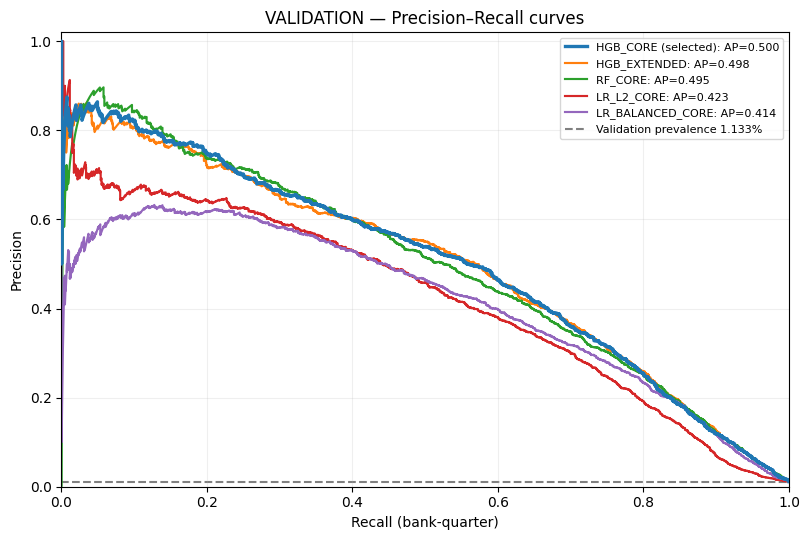

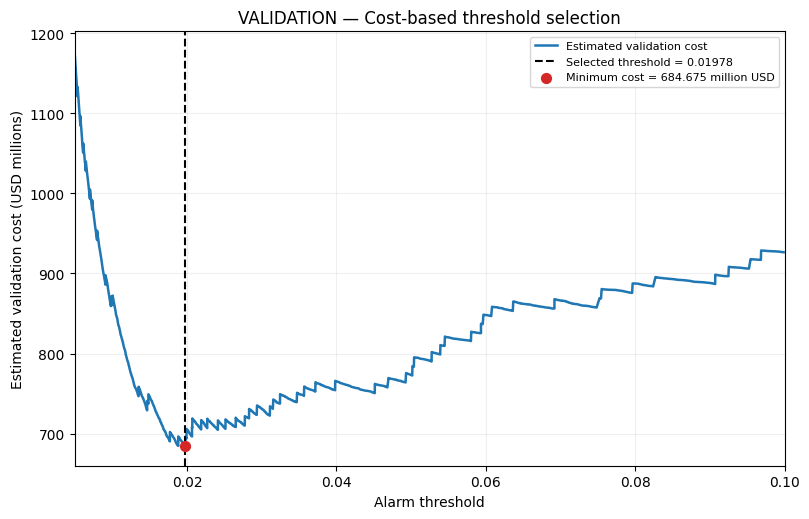

In [ ]:
# FIGURE 1 — VALIDATION Precision–Recall (omit only the constant-score Dummy curve).
# DummyClassifier(strategy='prior') assigns identical scores to every observation;
# plotting its two PR endpoints as a continuous diagonal is visually misleading.
# The dummy's AP and ROC-AUC are still included in validation_model_comparison.csv.
fig, ax = plt.subplots(figsize=(8.2, 5.5))
for name in val_results.loc[val_results['model'].ne('DUMMY_PRIOR'), 'model']:
    precision, recall, _ = precision_recall_curve(Y_VAL, val_scores[name])
    ap = average_precision_score(Y_VAL, val_scores[name])
    is_winner = (name == WINNER)
    label = f'{name}{" (selected)" if is_winner else ""}: AP={ap:.3f}'
    ax.plot(recall, precision, label=label,
            linewidth=2.4 if is_winner else 1.55,
            zorder=4 if is_winner else 2)
ax.axhline(float(Y_VAL.mean()), linestyle='--', color='gray', linewidth=1.5,
           label=f'Validation prevalence {Y_VAL.mean():.3%}', zorder=1)
ax.set(xlabel='Recall (bank-quarter)', ylabel='Precision',
       title='VALIDATION — Precision–Recall curves')
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.legend(fontsize=8, loc='upper right')
ax.grid(alpha=.2)
fig.tight_layout()
fig.savefig(OUT/'Figure_1_Validation_PR.png', dpi=180)
plt.show()
plt.close(fig)

# FIGURE 2 — VALIDATION estimated cost versus alarm threshold (zoom near optimum).
# This is a visualization-only change. VAL_COST_CURVE, THRESHOLD, C_FN and C_FP
# are calculated upstream and are not modified or retuned in this cell.
zoom_left = max(0.0, THRESHOLD * 0.25)
zoom_right = min(1.0, max(0.10, THRESHOLD * 5.0))
visible = VAL_COST_CURVE.loc[
    VAL_COST_CURVE['threshold'].between(zoom_left, zoom_right)
].copy()
assert len(visible) >= 2, 'Insufficient points around the selected threshold.'
closest = int(np.abs(VAL_COST_CURVE['threshold'].to_numpy() - THRESHOLD).argmin())
selected = VAL_COST_CURVE.iloc[closest]
assert np.isclose(float(selected['threshold']), THRESHOLD, rtol=1e-12, atol=1e-12)

# FDIC COST source is in USD thousands -> plot USD millions for readability.
# When no empirical COST is available, upstream uses relative unit costs instead.
have_usd_cost = MEDIAN_COST is not None
scale = 1000.0 if have_usd_cost else 1.0
cost_units = 'Estimated validation cost (USD millions)' if have_usd_cost else 'Estimated validation cost (relative units)'
optimum_cost = float(selected['estimated_cost']) / scale

fig, ax = plt.subplots(figsize=(8.2, 5.3))
ax.plot(visible['threshold'], visible['estimated_cost'] / scale,
        color='tab:blue', linewidth=1.8, label='Estimated validation cost')
ax.axvline(THRESHOLD, color='black', linestyle='--', linewidth=1.5,
           label=f'Selected threshold = {THRESHOLD:.5f}')
ax.scatter([THRESHOLD], [optimum_cost], color='tab:red', s=50, zorder=5,
           label=f'Minimum cost = {optimum_cost:,.3f}'+(' million USD' if have_usd_cost else ' units'))
ax.set(xlabel='Alarm threshold', ylabel=cost_units,
       title='VALIDATION — Cost-based threshold selection')
ax.set_xlim(zoom_left, zoom_right)
ax.grid(alpha=.2)
ax.legend(fontsize=8, loc='best')
fig.tight_layout()
fig.savefig(OUT/'Figure_2_Validation_Threshold_Cost.png', dpi=180)
plt.show()
plt.close(fig)


## 7. Freeze the development decision **before touching TEST**
Save the selected model, feature list, threshold, cost scenario and validation results. Once a TEST result exists, this cell refuses to overwrite the protocol. No retraining after Test results are observed.

In [ ]:
PROTOCOL_PATH=OUT/'locked_development_protocol.json'
TEST_RESULT_PATH=OUT/'FINAL_TEST_EVALUATION.json'
model_path=OUT/'chosen_train_fitted_model.joblib'
protocol={
    'project':'FDIC_BANK_FAILURE_PART5_V1',
    'selection_data':'TRAIN_FIT_VALIDATION_TUNE_ONLY',
    'train_range':SPLIT_INFO['split_bounds']['TRAIN'],
    'validation_range':SPLIT_INFO['split_bounds']['VALIDATION'],
    'test_range':SPLIT_INFO['split_bounds']['TEST'],
    'label_horizon_quarters':4,'feature_reporting_lag_quarters':1,
    'model':WINNER,'feature_group':WINNER_INFO['group'],
    'model_feature_columns':WINNER_INFO['features'],
    'feature_count':len(WINNER_INFO['features']),
    'threshold':float(THRESHOLD),
    'primary_model_selection':'validation_average_precision',
    'development_cost_source':COST_SOURCE,
    'development_median_fdic_cost':MEDIAN_COST,
    'assumed_false_alarm_cost_fraction':FALSE_ALARM_COST_FRACTION,
    'false_negative_cost_proxy':C_FN,
    'false_positive_cost_scenario':C_FP,
    'random_seed':SEED,
    'validation_average_precision':float(val_results.set_index('model').loc[WINNER,'average_precision']),
    'test_not_used_in_selection':True,
}
# Excludes timestamps: deterministic protocol for reruns.
current_payload=json.dumps(protocol,sort_keys=True,separators=(',',':'),ensure_ascii=False)
current_hash=hashlib.sha256(current_payload.encode('utf-8')).hexdigest()
if TEST_RESULT_PATH.exists():
    assert PROTOCOL_PATH.exists(),'Test file exists but locked protocol missing: investigate.'
    prior=json.loads(PROTOCOL_PATH.read_text(encoding='utf-8'))
    assert prior['hash_sha256']==current_hash, 'HALT: development protocol changed after TEST was evaluated.'
else:
    if PROTOCOL_PATH.exists():
        prior=json.loads(PROTOCOL_PATH.read_text(encoding='utf-8'))
        if prior['hash_sha256'] != current_hash:
            warnings.warn('Development protocol changed before TEST. Replace pre-TEST lock with new development choices.')
    PROTOCOL_PATH.write_text(json.dumps({'hash_sha256':current_hash,'protocol':protocol},indent=2,ensure_ascii=False),encoding='utf-8')
    joblib.dump(WINNER_INFO,model_path,compress=3)
assert model_path.exists(),'Selected model artifact unavailable.'
print('DEVELOPMENT PROTOCOL LOCKED:',current_hash)
print('Model:',WINNER,'| frozen threshold:',THRESHOLD)

DEVELOPMENT PROTOCOL LOCKED: dda69fdec8a2d38e7c7de6bca4bedbdb87ce37403b06acbec1e28ec43c300990
Model: HGB_CORE | frozen threshold: 0.019781976086460606


## 8. Optional interpretability (VALIDATION only)
Logistic coefficients are interpretable as standardized-feature associations; non-linear models can use permutation importance on a **development sample**. This section is intentionally descriptive and **does not modify** the locked selection decision. Runtime is limited by sampling.

In [ ]:
from sklearn.inspection import permutation_importance
RUN_VALIDATION_IMPORTANCE = True  # True for a small development-only sensitivity check.
if RUN_VALIDATION_IMPORTANCE:
    from sklearn.model_selection import train_test_split
    selected=WINNER_INFO['features']
    # Keep every positive and random negative subset, validation only; this changes AP baseline.
    rng=np.random.default_rng(SEED)
    pos=np.flatnonzero(Y_VAL==1)
    neg=np.flatnonzero(Y_VAL==0)
    pick=np.sort(np.r_[pos,rng.choice(neg,min(5000,len(neg)),replace=False)])
    Xsub=val[selected].iloc[pick].to_numpy(dtype=np.float32)
    ysub=Y_VAL[pick]
    perm=permutation_importance(WINNER_INFO['model'],Xsub,ysub,n_repeats=2,
                                scoring='average_precision',random_state=SEED,n_jobs=1)
    imp=pd.DataFrame({'feature':selected,'importance_mean':perm.importances_mean,
                      'importance_std':perm.importances_std}).sort_values('importance_mean',ascending=False)
    imp.to_csv(OUT/'validation_permutation_importance.csv',index=False)
    display(imp.head(15))
else:
    print('Optional validation-only permutation importance skipped.')

,feature,importance_mean,importance_std
6,F_TEXAS_PROXY,0.085152,0.000587
0,F_EQUITY_ASSET,0.044212,0.004386
8,F_ROE_PCT,0.006187,0.000468
11,F_SECURITIES_ASSET,0.006186,0.000004
13,F_COREDEP_SHARE,0.004782,0.000270
7,F_ROA_PCT,0.004631,0.000228
1,F_PCA_LEVERAGE_PCT,0.004212,0.000234
22,F_NPL_CHANGE_4Q,0.003749,0.000226
17,F_CONSTRUCTION_LOAN_SHARE,0.003066,0.000064
9,F_NIM_PCT,0.002414,0.000993


## 9. Spark MLlib short demonstration (**development only**)
Spark MLlib Logistic Regression runs in **local mode** on a clearly labeled, deterministic development sample for demonstration. It does **not** set the winning model, cost threshold or TEST results. Downsampling nonfailures changes class prevalence, so its scores should **not** be treated as calibrated four-quarter probabilities. Spark `areaUnderPR` and sklearn AP are not numerically identical definitions.

In [ ]:
SPARK_REPORT={'status':'SKIPPED','mode':'local[2]'}
if RUN_SPARK_MLLIB:
    try:
        from pyspark.sql import SparkSession
        from pyspark.ml.feature import VectorAssembler
        from pyspark.ml.classification import LogisticRegression as SparkLogisticRegression
        from pyspark.ml.evaluation import BinaryClassificationEvaluator
        spark=(SparkSession.builder.appName('FDIC_Part5_MLlib_Demo')
               .master('local[2]')
               .config('spark.sql.shuffle.partitions','4')
               .config('spark.ui.showConsoleProgress','false')
               .getOrCreate())
        spark.sparkContext.setLogLevel('ERROR')
        rng=np.random.default_rng(SEED)
        tr_pos=np.flatnonzero(Y_TRAIN==1); tr_neg=np.flatnonzero(Y_TRAIN==0)
        va_pos=np.flatnonzero(Y_VAL==1); va_neg=np.flatnonzero(Y_VAL==0)
        tr_pick=np.sort(np.r_[tr_pos,rng.choice(tr_neg,min(50000,len(tr_neg)),replace=False)])
        va_pick=np.sort(np.r_[va_pos,rng.choice(va_neg,min(20000,len(va_neg)),replace=False)])
        cols=FEATURE_SETS['CORE']
        def to_spark_pdf(src,idx):
            df=src.iloc[idx][cols+['fail_within_4q']].copy()
            df[cols]=df[cols].astype('float64')
            return df.rename(columns={'fail_within_4q':'label'}).astype({'label':'float64'})
        s_train=spark.createDataFrame(to_spark_pdf(train,tr_pick))
        s_val=spark.createDataFrame(to_spark_pdf(val,va_pick))
        assembler=VectorAssembler(inputCols=cols,outputCol='features',handleInvalid='error')
        s_train=assembler.transform(s_train).select('label','features').cache();s_train.count()
        s_val=assembler.transform(s_val).select('label','features').cache();s_val.count()
        spark_lr=SparkLogisticRegression(featuresCol='features',labelCol='label',maxIter=35,
                                        regParam=0.05,elasticNetParam=0.0)
        smodel=spark_lr.fit(s_train)
        spred=smodel.transform(s_val).cache();spred.count()
        epr=BinaryClassificationEvaluator(labelCol='label',rawPredictionCol='rawPrediction',metricName='areaUnderPR')
        eroc=BinaryClassificationEvaluator(labelCol='label',rawPredictionCol='rawPrediction',metricName='areaUnderROC')
        SPARK_REPORT={'status':'PASS','mode':'local[2]','train_rows':len(tr_pick),
                      'validation_rows':len(va_pick),'core_features':len(cols),
                      'spark_area_under_pr':float(epr.evaluate(spred)),
                      'spark_area_under_roc':float(eroc.evaluate(spred)),
                      'warning':'case-control development sample; not calibrated or comparable to full-cohort sklearn AP'}
        (OUT/'Spark_MLlib_Validation_ExecutedPlan.txt').write_text(spred._jdf.queryExecution().executedPlan().toString(),encoding='utf-8')
        spred.unpersist();s_train.unpersist();s_val.unpersist()
        spark.stop()
    except Exception as exc:
        SPARK_REPORT={'status':'ERROR','mode':'local[2]','error_type':type(exc).__name__,
                      'error_message':str(exc)[:1000]}
        print('Spark MLlib demo failed; inspect Colab Java/PySpark installation:',exc)
(OUT/'spark_mllib_demo_report.json').write_text(json.dumps(SPARK_REPORT,indent=2),encoding='utf-8')
print('Spark demo:',SPARK_REPORT)

Spark demo: {'status': 'PASS', 'mode': 'local[2]', 'train_rows': 58278, 'validation_rows': 21791, 'core_features': 44, 'spark_area_under_pr': 0.7583908947948345, 'spark_area_under_roc': 0.9571289782244558, 'warning': 'case-control development sample; not calibrated or comparable to full-cohort sklearn AP'}


## 10. Development audit and lightweight reproducibility bundle
These checks do not access the TEST Parquet. Inspect `development_acceptance_gates.csv`, `validation_model_comparison.csv`, and `validation_threshold_cost_sensitivity.csv` before enabling the final Test cell.

In [ ]:
DEV_GATES={
 'TRAIN_ONLY_PREPROCESSOR': PREP_INFO['fit_split']=='TRAIN_ONLY',
 'FOUR_QUARTER_LABEL': SPLIT_INFO['label_horizon_quarters']==4,
 'FOUR_QUARTER_EMBARGO': all(SPLIT_INFO['split_bounds'][k] == v for k,v in {
    'TRAIN':['1984Q1','2005Q4'],'VALIDATION':['2007Q1','2011Q4'],'TEST':['2013Q1','2025Q2']}.items()),
 'NO_TEST_DATA_LOADED_FOR_DEVELOPMENT':'test' not in globals(),
 'FEATURES_AND_TARGET_SEPARATE':not(set(FEATURES) & set(META)),
 'SELECTION_ON_VALIDATION_AP':WINNER in models and PRIMARY_SELECTION_METRIC=='validation_average_precision',
 'COST_THRESHOLD_FROM_VALIDATION':np.isfinite(THRESHOLD) and THRESHOLD>=0,
 'SPARK_MLLIB_DEMO_PASS':SPARK_REPORT['status']=='PASS' if RUN_SPARK_MLLIB else True,
 'FROZEN_PROTOCOL_SAVED':PROTOCOL_PATH.is_file(),
}
DEV_GATES_DF=pd.DataFrame([{'gate':k,'passed':bool(v)} for k,v in DEV_GATES.items()])
DEV_GATES_DF.to_csv(OUT/'development_acceptance_gates.csv',index=False)
if not DEV_GATES_DF.passed.all():
    print('Some development gates failed (do not evaluate TEST yet):')
    display(DEV_GATES_DF)
else:
    print('DEVELOPMENT CHECKS:',len(DEV_GATES_DF),'/',len(DEV_GATES_DF),'PASS')
versions={name:version for name,version in [('python',platform.python_version()),
    ('pandas',pd.__version__),('numpy',np.__version__),('sklearn',sklearn.__version__)]}
(OUT/'runtime_versions.json').write_text(json.dumps(versions,indent=2),encoding='utf-8')

def pack_reports():
    archive_path=OUT/'FDIC_Part5_Modeling_Validation_Reports.zip'
    with zipfile.ZipFile(archive_path,'w',zipfile.ZIP_DEFLATED) as z:
        for f in sorted(OUT.iterdir()):
            if f.is_file() and f != archive_path and f.suffix.lower() in ('.json','.csv','.txt','.png'):
                z.write(f,arcname=f.name)
    with zipfile.ZipFile(archive_path) as z:
        assert z.testzip() is None
        print('Report ZIP:',archive_path,'| files:',len(z.namelist()))
    return archive_path
pack_reports()

DEVELOPMENT CHECKS: 9 / 9 PASS
Report ZIP: /content/drive/MyDrive/FDIC_Bank_Failure_Project/outputs/part5/modeling_validation_v1/FDIC_Part5_Modeling_Validation_Reports.zip | files: 17


PosixPath('/content/drive/MyDrive/FDIC_Bank_Failure_Project/outputs/part5/modeling_validation_v1/FDIC_Part5_Modeling_Validation_Reports.zip')

## 11. FINAL TEST — turn on only after freezing the protocol
This is a **single held-out evaluation**. It reads TEST only here. On first execution it creates `FINAL_TEST_EVALUATION.json`, which prevents future reruns by default. **Do not change the model, feature set or threshold based on the results.** If the development gates show Spark failed, resolve that first; the complete Part 5 submission requires the MLlib demonstration.

**Figure-only reruns:** Keep `RUN_FINAL_TEST=False`. The Figure 3 PNG from the original single TEST evaluation is valid and should be reused. Do not rerun TEST just to redraw an unchanged curve.

In [ ]:
if not RUN_FINAL_TEST:
    print('FINAL TEST remains LOCKED. Review the development reports first.')
else:
    assert DEV_GATES_DF.passed.all(),'Development checks did not all PASS: DO NOT unlock TEST.'
    assert PROTOCOL_PATH.exists() and model_path.exists()
    if TEST_RESULT_PATH.exists() and not ALLOW_TEST_REEVALUATION:
        raise RuntimeError('FINAL TEST ALREADY EVALUATED. Preserve the locked test and use existing report.')
    stored=json.loads(PROTOCOL_PATH.read_text(encoding='utf-8'))
    assert stored['hash_sha256']==current_hash, 'Protocol changed after freeze.'
    saved=joblib.load(model_path)
    assert saved['features']==WINNER_INFO['features'] and stored['protocol']['model']==WINNER
    # FIRST test data access occurs here.
    test=load_split('TEST')
    assert len(test)==int(expected.loc['TEST','rows'])
    assert test.loc[test.fail_within_4q.eq(1),'CERT'].nunique()>=50
    X_TEST=test[saved['features']].to_numpy(dtype=np.float32,copy=True)
    Y_TEST=test.fail_within_4q.to_numpy(dtype=np.int8)
    TEST_PROB=saved['model'].predict_proba(X_TEST)[:,1]
    test_rank=ranking_metrics(Y_TEST,TEST_PROB,'TEST',WINNER)
    test_fixed=fixed_threshold_metrics(test,TEST_PROB,THRESHOLD,'TEST',WINNER)
    test_cost=(test_fixed['fp']*C_FP +
               (test_fixed['failed_banks']-test_fixed['failed_banks_alerted_within_4q'])*C_FN)
    test_report={'executed_utc':datetime.now(timezone.utc).isoformat(),
                 'locked_protocol_sha256':current_hash,
                 'selection_was_development_only':True,
                 'test_rank_metrics':test_rank,
                 'test_fixed_threshold_metrics':test_fixed,
                 'test_estimated_cost_source_units':float(test_cost),
                 'false_alarm_cost_is_scenario':True}
    # A durable, one-time report is written before plotting.
    TEST_RESULT_PATH.write_text(json.dumps(test_report,indent=2,ensure_ascii=False),encoding='utf-8')
    pd.DataFrame([test_rank]).to_csv(OUT/'FINAL_TEST_Ranking_Metrics.csv',index=False)
    pd.DataFrame([test_fixed]).to_csv(OUT/'FINAL_TEST_Threshold_Metrics.csv',index=False)
    fig,ax=plt.subplots(figsize=(7.5,5.5))
    prec,rec,_=precision_recall_curve(Y_TEST,TEST_PROB)
    ax.plot(rec,prec,label=f'{WINNER} | Test AP={test_rank["average_precision"]:.4f}')
    ax.axhline(Y_TEST.mean(),ls='--',color='gray',label=f'Test prevalence {Y_TEST.mean():.3%}')
    ax.set(xlabel='Recall',ylabel='Precision',title='LOCKED TEST — Precision–Recall')
    ax.legend();ax.grid(alpha=.2);fig.tight_layout()
    fig.savefig(OUT/'Figure_3_FINAL_TEST_PR.png',dpi=180);plt.show();plt.close(fig)
    print('FINAL TEST evaluated once. No further selection or threshold tuning allowed.')
    print(json.dumps(test_report,indent=2))
    pack_reports()

FINAL TEST remains LOCKED. Review the development reports first.


## 12. Reporting instructions and interpretation guardrails

**What to include in Part 5 report**
1. Table with model candidates, TRAIN-only fitting, core/extended feature policy, and validated temporal embargo.
2. VALIDATION model comparison using Average Precision (AP), ROC-AUC and Brier; compare AP to the **validation prevalence**.
3. Alarm policy from development COST evidence + explicit false-alarm cost assumptions. Show **cost sensitivity**, FP bank-quarters, and the number of distinct failures captured. Explain that FDIC `COST` is not a directly avoidable supervisory loss.
4. One locked TEST evaluation: AP/ROC-AUC/Brier, fixed-threshold precision/recall, false alarms per 1,000 negatives, distinct failed banks detected; **never retune** after seeing TEST.
5. Spark MLlib demo on development only, with exact sample sizes, executed plan, Spark `areaUnderPR` and runtime mode `local[2]`; do not call this a distributed multi-node cluster.
6. Limitations: model-relevant 4-quarter outcome, 1-quarter financial reporting lag as **assumption** due missing release vintages, merger/censoring exclusions, crisis and class-prevalence shift, repeated bank-quarters, historical FDIC resolution cost revisions, uncertainty in false-alarm cost.

**Sources and methods**
- Assignment: `final_report_bft65b.pdf`, Parts 4–5, label/test requirements.
- FDIC official bank data dictionary: https://api.fdic.gov/banks/docs/
- FDIC research on financial predictors, CAMELS/SCOR: https://www.fdic.gov/system/files/2024-07/cfr-wp2017-04.pdf
- scikit-learn Average Precision: https://scikit-learn.org/stable/modules/generated/sklearn.metrics.average_precision_score.html
- scikit-learn Histogram Gradient Boosting: https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.HistGradientBoostingClassifier.html
- Spark BinaryClassificationEvaluator: https://spark.apache.org/docs/latest/api/python/reference/api/pyspark.ml.evaluation.BinaryClassificationEvaluator.html

**Final ZIP path:** `outputs/part5/modeling_validation_v1/FDIC_Part5_Modeling_Validation_Reports.zip`. Large parquet/model artifacts stay on Drive and are not included in report ZIP.

## Figure revision notes (visualization only)

- Figure 1: `DUMMY_PRIOR` diagonal removed from the figure only; all metrics and model selection remain unchanged.
- Figure 2: zoom around the chosen threshold, display FDIC COST in USD millions when available, and mark the minimum. The original cost optimization remains unchanged.
- Figure 3: retained from the original locked TEST evaluation. No new TEST access is required to update Figures 1 and 2.
- `RUN_FINAL_TEST=False` is now the default, preventing accidental evaluation on a restart.

**To update the plots:** execute the development sections of this notebook through Section 10; the chart cell updates `Figure_1_Validation_PR.png` and `Figure_2_Validation_Threshold_Cost.png` in the same output folder. The existing `Figure_3_FINAL_TEST_PR.png` remains the authoritative locked TEST chart. The final report ZIP is repacked in Section 10.